In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ydata_profiling import ProfileReport

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LinearRegression, SGDRegressor, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
r2_score, mean_absolute_error, mean_squared_error,
accuracy_score, precision_score, recall_score,
confusion_matrix, classification_report                     
)
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    MinMaxScaler,
    OrdinalEncoder,
    OneHotEncoder,
    LabelEncoder
)

C:\Users\User\miniconda3\envs\ai_master\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
%matplotlib inline
df=pd.read_csv("./dataset/adult_income.csv")
df.sample(5)

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
34836,56,Private,364899,Doctorate,16,Married-civ-spouse,Prof-specialty,Husband,White,Male,7688,0,65,United-States,>50K.
21613,36,Private,130589,Some-college,10,Divorced,Exec-managerial,Not-in-family,White,Male,0,0,45,United-States,<=50K
12678,17,Private,151141,12th,8,Never-married,Sales,Own-child,White,Male,0,0,20,United-States,<=50K
23578,56,Private,181220,Bachelors,13,Married-civ-spouse,Sales,Husband,White,Male,0,0,40,United-States,>50K
28614,19,Private,138760,HS-grad,9,Never-married,Machine-op-inspct,Own-child,White,Male,0,0,40,United-States,<=50K


In [3]:
# profile=ProfileReport(df,title='adult_income Profile Report')
# profile.to_file('adult_income.html')

In [4]:
# print(df.head())
# print(df.shape)
# print(df.columns)
print(df.info())
# print(df.isnull().sum())

column=['age', 'workclass', 'education-num',
       'marital-status', 'occupation', 'relationship', 'race', 'sex',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country']

encode_col=['workclass','marital-status','occupation','relationship','race','sex','native-country']
scaling_col=['age','hours-per-week']


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48842 non-null  int64 
 1   workclass       48842 non-null  object
 2   fnlwgt          48842 non-null  int64 
 3   education       48842 non-null  object
 4   education-num   48842 non-null  int64 
 5   marital-status  48842 non-null  object
 6   occupation      48842 non-null  object
 7   relationship    48842 non-null  object
 8   race            48842 non-null  object
 9   sex             48842 non-null  object
 10  capital-gain    48842 non-null  int64 
 11  capital-loss    48842 non-null  int64 
 12  hours-per-week  48842 non-null  int64 
 13  native-country  48842 non-null  object
 14  income          48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB
None


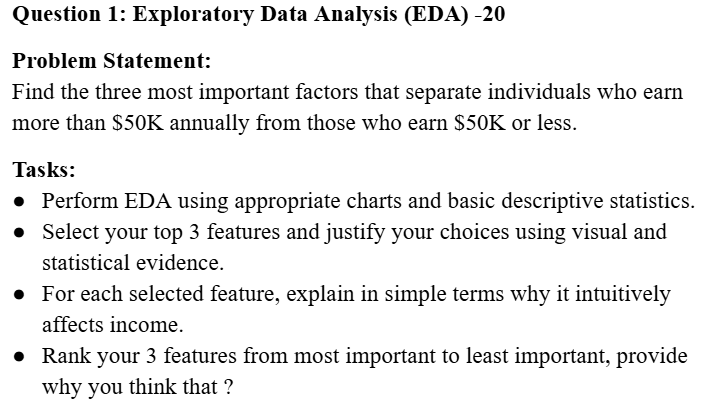

income
<=50K     24720
<=50K.    12435
>50K       7841
>50K.      3846
Name: count, dtype: int64
income
0    37155
1    11687
Name: count, dtype: int64
age                  0
workclass         2799
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        2809
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
native-country     857
income               0
dtype: int64
(48790, 15)
relationship
Wife              46.9
Husband           44.9
Not-in-family     10.2
Unmarried          6.0
Other-relative     3.5
Own-child          1.5
Name: income, dtype: float64


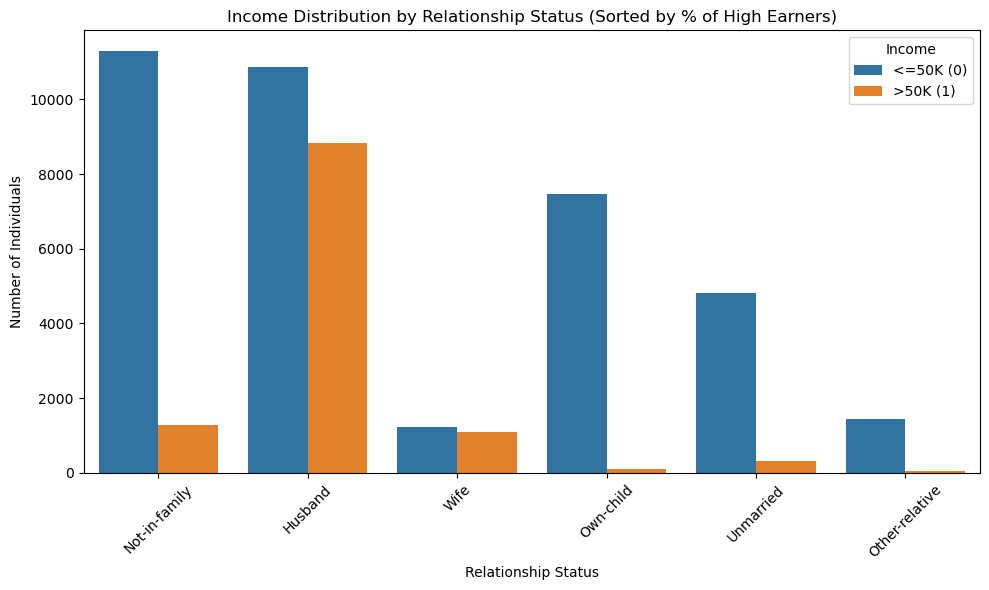

marital-status
Married-civ-spouse       44.6
Married-AF-spouse        37.8
Divorced                 10.1
Married-spouse-absent     9.3
Widowed                   8.4
Separated                 6.5
Never-married             4.6
Name: income, dtype: float64


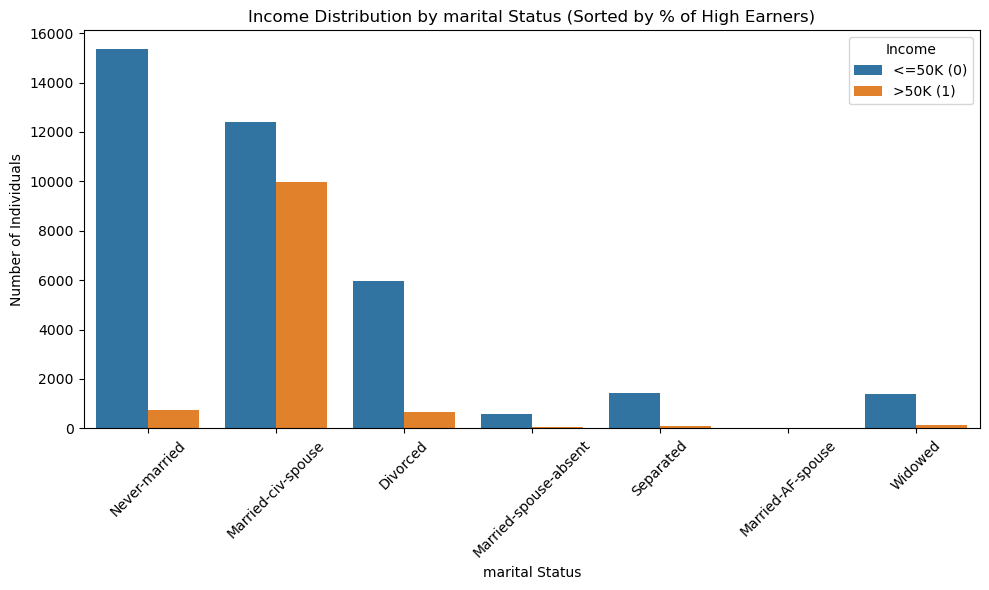

income
1    21.3
0     4.2
Name: has_capital_gain, dtype: float64


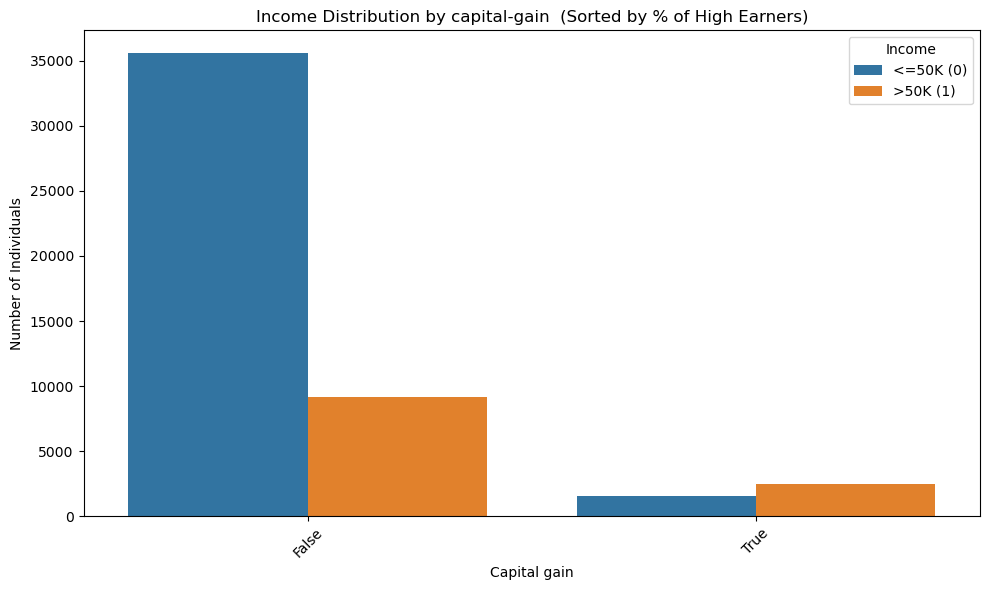

[0.06592086 0.04243885 0.01258303 0.10873391 0.05081312 0.11459698
 0.00568982 0.02543176 0.00563811 0.0643025  0.08266444 0.03607066]
           feature  mutual_information
0     relationship              0.1146
1   marital-status              0.1087
2     capital-gain              0.0827
3              age              0.0659
4    education-num              0.0643
5       occupation              0.0508
6   hours-per-week              0.0424
7     capital-loss              0.0361
8              sex              0.0254
9        workclass              0.0126
10            race              0.0057
11  native-country              0.0056


In [5]:
df=pd.read_csv("./dataset/adult_income.csv")

print(df["income"].value_counts())
df.loc[df["income"].str.contains('<=50K'),"income"]='0'
df.loc[df["income"].str.contains('>50K'),"income"]='1'
df["income"]=df["income"].astype(int)

print(df["income"].value_counts())

non_numeric_cols=df.select_dtypes(include=['object']).columns.tolist()
numeric_cols=df.select_dtypes(include=['number']).columns.tolist()

for col in non_numeric_cols:
    df[col]=df[col].str.strip().replace('?',np.nan)

print(df.isnull().sum())
df=df.drop_duplicates().copy()

print(df.shape)

print(df.groupby("relationship")['income'].mean().mul(100).sort_values(ascending=False).round(1))
plt.figure(figsize=(10, 6))

sns.countplot(data=df,x="relationship",hue="income")
plt.title("Income Distribution by Relationship Status (Sorted by % of High Earners)")
plt.xlabel("Relationship Status")
plt.ylabel("Number of Individuals")
plt.xticks(rotation=45)
plt.legend(title="Income", labels=["<=50K (0)", ">50K (1)"])

plt.tight_layout()
plt.show()

print(df.groupby("marital-status")['income'].mean().mul(100).sort_values(ascending=False).round(1))

plt.figure(figsize=(10, 6))

sns.countplot(data=df,x="marital-status",hue="income")
plt.title("Income Distribution by marital Status (Sorted by % of High Earners)")
plt.xlabel("marital Status")
plt.ylabel("Number of Individuals")
plt.xticks(rotation=45)
plt.legend(title="Income", labels=["<=50K (0)", ">50K (1)"])

plt.tight_layout()
plt.show()


tmpdf=df.assign(
    has_capital_gain=df["capital-gain"]>0
         )
print(tmpdf.groupby('income')["has_capital_gain"].mean().mul(100).sort_values(ascending=False).round(1))
plt.figure(figsize=(10, 6))

sns.countplot(data=tmpdf,x="has_capital_gain",hue="income")
plt.title("Income Distribution by capital-gain  (Sorted by % of High Earners)")
plt.xlabel("Capital gain")
plt.ylabel("Number of Individuals")
plt.xticks(rotation=45)
plt.legend(title="Income", labels=["<=50K (0)", ">50K (1)"])

plt.tight_layout()
plt.show()

X=df.drop(columns=['income','education','fnlwgt'])
y=df['income']

non_numeric_cols=X.select_dtypes(include=['object']).columns.tolist()
numeric_cols=X.select_dtypes(include=['number']).columns.tolist()

mic=X.copy()

encode_col=['workclass','marital-status','occupation','relationship','race','sex','native-country']
scaling_col=['age','hours-per-week']

cat_pipe=Pipeline([
    ('imputer',SimpleImputer(missing_values=np.nan ,strategy="most_frequent")),
    ('le',OrdinalEncoder())
])

num_pipe=Pipeline([
    ('imputer',SimpleImputer(missing_values=np.nan ,strategy="median")),
    ('ss',StandardScaler())
])

imputer_transformer=ColumnTransformer(
    transformers=[
        ('numerical',num_pipe,scaling_col),
        ('categorical',cat_pipe,encode_col)
    ],
    remainder='passthrough',verbose_feature_names_out=False
).set_output(transform='pandas')

imputer_transformer.fit(mic)

mic = imputer_transformer.transform(mic)
# for col in numeric_cols:
#     mic[col] = mic[col].fillna(
#         mic[col].median()
#     )

# for col in non_numeric_cols:
#     mic[col] = (
#         mic[col]
#         .fillna("Missing")
#         .astype("category")
#         .cat.codes
#     )
    
discrete_features = [
    col in non_numeric_cols
    for col in mic.columns
]

mi_score=mutual_info_classif(
    mic,y,discrete_features=discrete_features,random_state=42
)
print(mi_score)

feature_ranking = (
    pd.DataFrame({
        "feature": mic.columns,
        "mutual_information": mi_score
    })
    .sort_values(
        "mutual_information",
        ascending=False
    )
    .reset_index(drop=True)
)

print(feature_ranking.round(4))

In [6]:
mic.corr(method='spearman')['age'].abs().sort_values(ascending=False)

age               1.000000
marital-status    0.372539
relationship      0.321826
hours-per-week    0.146263
capital-gain      0.124305
sex               0.100294
workclass         0.070645
education-num     0.063026
capital-loss      0.057455
race              0.027344
occupation        0.007345
native-country    0.006555
Name: age, dtype: float64

In [7]:
# df["income"]=df["income"].str.contains('>').astype(int)
# df[df["income"]=='<=50K']

In [8]:
# df["income"]=df["income"].astype(int)
# print(type(df["income"][0]))
# df["income"].value_counts()

# df.loc[df["income"].str.contains('<=50K'),"income"]='0'
# df.loc[df["income"].str.contains('>50K'),"income"]='1'
# df["income"]=df["income"].astype(int)

df["income"].value_counts()
# df[df["income"]=='<=50K']

income
0    37109
1    11681
Name: count, dtype: int64

In [9]:
non_numeric_cols=df.select_dtypes(include=['object']).columns.tolist()
numeric_cols=df.select_dtypes(include=['number']).columns.tolist()

# sns.boxplot(df[col])
# type(numeric_cols)
print(numeric_cols ,non_numeric_cols)

# for col in numeric_cols:
#     # plt.figure()
#     sns.boxplot(x=df[col])
#     plt.title(f"Box Plot of {col}")
#     plt.show()

['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week', 'income'] ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


In [10]:
for col in non_numeric_cols:
    df[col]=df[col].str.strip().replace('?',np.nan)

# for col in df.columns:
#     print(df[col].unique())
# df.isnull()
# data['workclass'].replace('?',np.nan)

In [11]:
df.isnull().sum()

age                  0
workclass         2795
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        2805
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
native-country     856
income               0
dtype: int64

In [12]:
df=df.drop_duplicates().copy()
df.sample(3)

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
31775,61,NaN,101602,Doctorate,16,Married-civ-spouse,NaN,Husband,White,Male,0,0,25,United-States,1
26870,38,Private,179488,Assoc-acdm,12,Divorced,Craft-repair,Not-in-family,White,Male,0,0,40,United-States,0
37711,51,Private,277471,HS-grad,9,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States,1


In [13]:
df.groupby("relationship")['income'].mean().mul(100).sort_values().round(1)



relationship
Own-child          1.5
Other-relative     3.5
Unmarried          6.0
Not-in-family     10.2
Husband           44.9
Wife              46.9
Name: income, dtype: float64

In [14]:
df.groupby("marital-status")['income'].mean().mul(100).sort_values().round(1)


marital-status
Never-married             4.6
Separated                 6.5
Widowed                   8.4
Married-spouse-absent     9.3
Divorced                 10.1
Married-AF-spouse        37.8
Married-civ-spouse       44.6
Name: income, dtype: float64

In [15]:

df.assign(
    has_capital_gain=df["capital-gain"]>0
         ).groupby('income')["has_capital_gain"].mean().mul(100)

income
0     4.160716
1    21.325229
Name: has_capital_gain, dtype: float64

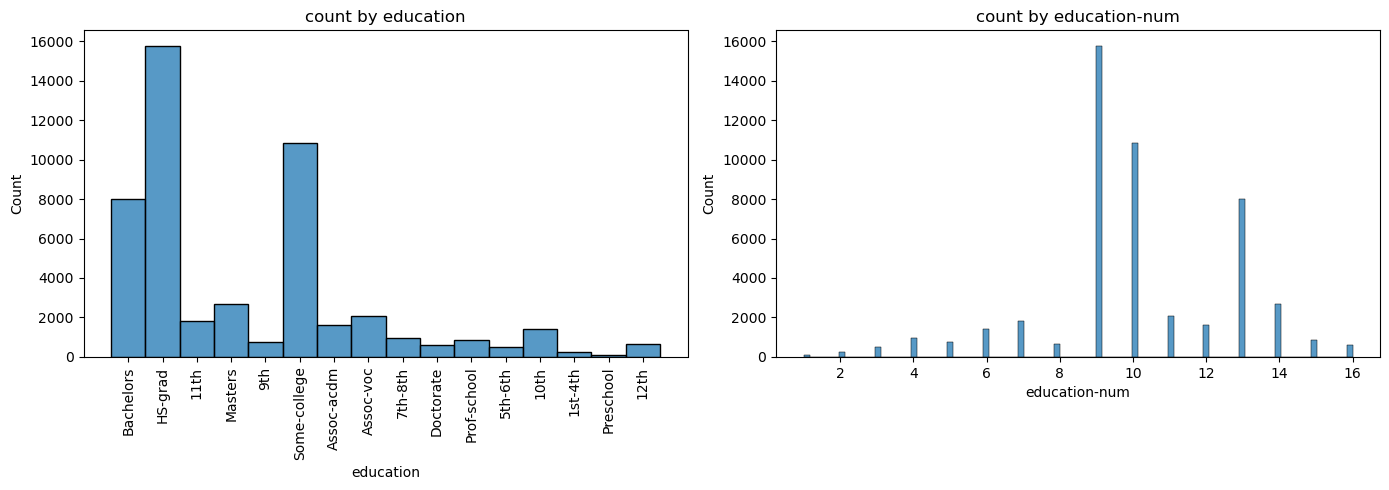

In [16]:


fig,axes=plt.subplots(1,2,figsize=(14,5))
sns.histplot(data=df,x='education',ax=axes[0])
axes[0].set_title('count by education')
axes[0].tick_params(axis='x', rotation=90) 

sns.histplot(data=df,x='education-num',ax=axes[1])
axes[1].set_title('count by education-num')
plt.tight_layout() 
plt.show()

In [17]:
# df['education']=df['education'].replace('Preschool', 'dropout')
# df['education']=df['education'].replace('10th', 'dropout')
# df['education']=df['education'].replace('11th', 'dropout')
# df['education']=df['education'].replace('12th', 'dropout')
# df['education']=df['education'].replace('1st-4th', 'dropout')
# df['education']=df['education'].replace('5th-6th', 'dropout')
# df['education']=df['education'].replace('7th-8th', 'dropout')
# df['education']=df['education'].replace('9th', 'dropout')
# df['education']=df['education'].replace('HS-Grad', 'HighGrad')
# df['education']=df['education'].replace('HS-grad', 'HighGrad')
# df['education']=df['education'].replace('Some-college', 'CommunityCollege')
# df['education']=df['education'].replace('Assoc-acdm', 'CommunityCollege')
# df['education']=df['education'].replace('Assoc-voc', 'CommunityCollege')
# df['education']=df['education'].replace('Bachelors', 'Bachelors')
# df['education']=df['education'].replace('Masters', 'Masters')
# df['education']=df['education'].replace('Prof-school', 'Masters')
# df['education']=df['education'].replace('Doctorate', 'Doctorate')

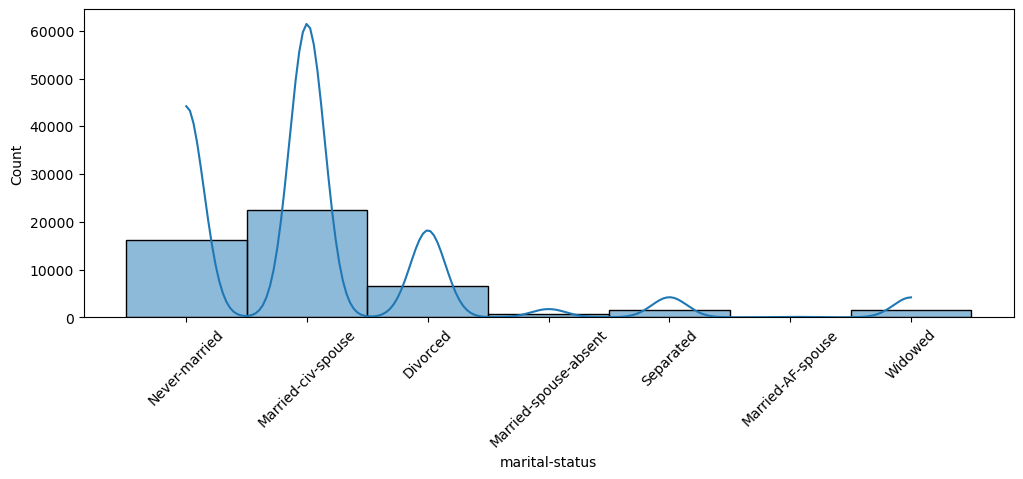

In [18]:
plt.figure(figsize=(12,4))
plt.xticks(rotation=45)
sns.histplot(data=df,x='marital-status',kde=True)
plt.show()

In [19]:
df['marital-status']=df['marital-status'].replace('Never-married', 'NotMarried')
df['marital-status']=df['marital-status'].replace('Married-AF-spouse', 'Married')
df['marital-status']=df['marital-status'].replace('Married-civ-spouse', 'Married')
df['marital-status']=df['marital-status'].replace('Married-spouse-absent', 'NotMarried')
df['marital-status']=df['marital-status'].replace('Separated', 'Separated')
df['marital-status']=df['marital-status'].replace('Divorced', 'Separated')
df['marital-status']=df['marital-status'].replace('Widowed', 'Widowed')

In [20]:
X=df.drop(['education'],axis=1)
y=df['income']
non_numeric_cols=X.select_dtypes(include=['object']).columns.tolist()
numeric_cols=X.select_dtypes(include=['number']).columns.tolist()
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
X_test



,age,workclass,fnlwgt,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
30304,40,Private,126868,9,Separated,Machine-op-inspct,Not-in-family,Black,Male,0,0,40,United-States,0
26731,84,Private,188328,9,Widowed,Prof-specialty,Not-in-family,White,Female,0,0,16,United-States,0
18008,71,NaN,128529,9,Widowed,NaN,Not-in-family,White,Female,0,0,20,United-States,0
20171,25,Private,71351,2,NotMarried,Other-service,Other-relative,White,Male,0,0,25,El-Salvador,0
10479,39,Private,204501,14,Married,Exec-managerial,Husband,White,Male,0,0,50,United-States,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32271,42,Local-gov,201495,10,Married,Protective-serv,Husband,White,Male,0,0,72,United-States,1
31579,38,Private,60135,9,NotMarried,Transport-moving,Not-in-family,White,Female,0,0,40,United-States,0
14039,35,Self-emp-inc,64874,12,NotMarried,Sales,Own-child,White,Male,0,0,40,United-States,0
25145,52,Private,270728,4,Married,Other-service,Husband,White,Male,0,0,48,Cuba,0


In [21]:
numeric_cols=['age',
  'fnlwgt',
  'education-num',
  'hours-per-week']
numeric_cols,non_numeric_cols

(['age', 'fnlwgt', 'education-num', 'hours-per-week'],
 ['workclass',
  'marital-status',
  'occupation',
  'relationship',
  'race',
  'sex',
  'native-country'])

In [22]:
imputer_transformer=ColumnTransformer(
    transformers=[
        ('numerical',SimpleImputer(missing_values=np.nan ,strategy="median"),numeric_cols),
        ('categorical',SimpleImputer(missing_values=np.nan ,strategy="most_frequent"),non_numeric_cols)
    ],
    remainder='passthrough',verbose_feature_names_out=False
).set_output(transform='pandas')

imputer_transformer.fit(X_train)

X_train = imputer_transformer.transform(X_train)
X_test = imputer_transformer.transform(X_test)
X_train.sample(5)

,age,fnlwgt,education-num,hours-per-week,workclass,marital-status,occupation,relationship,race,sex,native-country,capital-gain,capital-loss,income
12447,23.0,213955.0,9.0,40.0,Private,NotMarried,Adm-clerical,Own-child,Black,Male,United-States,0,2001,0
23769,51.0,145409.0,10.0,48.0,Private,Married,Craft-repair,Husband,White,Male,United-States,3103,0,1
36670,33.0,49027.0,9.0,40.0,Private,NotMarried,Machine-op-inspct,Not-in-family,White,Female,United-States,0,0,0
32292,41.0,318046.0,10.0,48.0,Private,Married,Transport-moving,Husband,White,Male,United-States,0,0,1
40297,30.0,90308.0,1.0,28.0,Private,NotMarried,Other-service,Unmarried,White,Male,El-Salvador,0,0,0


In [23]:
for col in numeric_cols:
    q1=X_train[col].quantile(0.25)
    q3=X_train[col].quantile(0.75)
    iqr=q3-q1
    min_lim=max(0,q1-1.5*iqr)
    max_lim=q3+1.5*iqr
    # print(min_lim,max_lim)
    # print(df[col].describe())
    X_train[col]=X_train[col].clip(min_lim,max_lim)
    X_test[col]=X_test[col].clip(min_lim,max_lim)
    # print(df[col].describe())

['age', 'fnlwgt', 'education-num', 'hours-per-week'] ['workclass', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


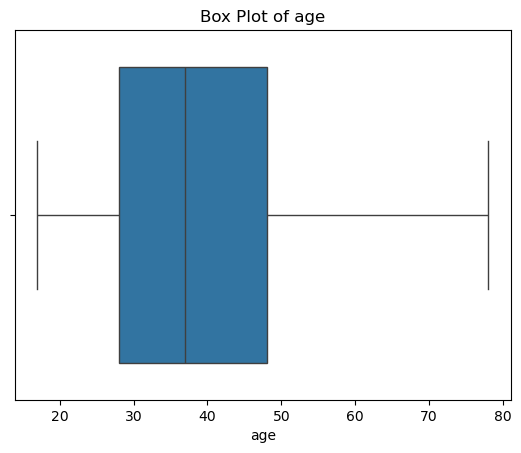

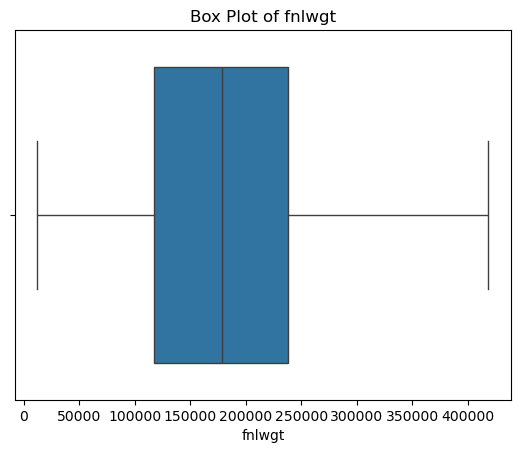

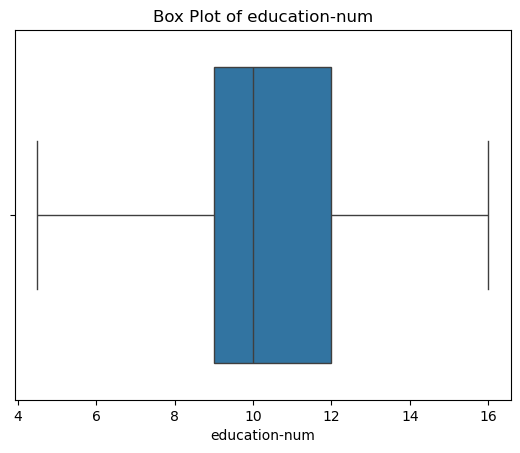

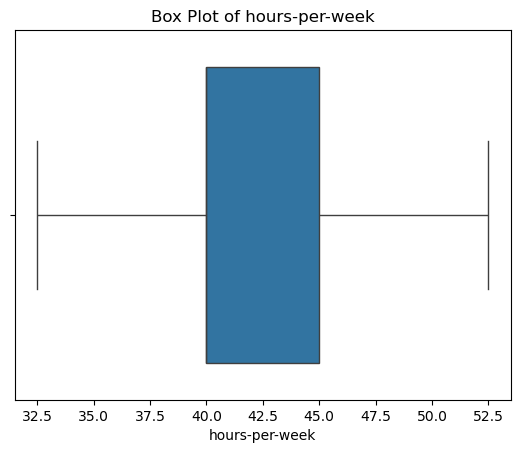

In [24]:

# sns.boxplot(df[col])
# type(numeric_cols)
print(numeric_cols ,non_numeric_cols)

for col in numeric_cols:
    # plt.figure()
    sns.boxplot(x=X_train[col])
    plt.title(f"Box Plot of {col}")
    plt.show()

In [25]:
for col in non_numeric_cols:
    print(col,'=>',type(X_train[col][0]), '=>>',X_train[col].unique())

workclass => <class 'str'> =>> ['Private' 'Local-gov' 'Self-emp-not-inc' 'Federal-gov' 'State-gov'
 'Self-emp-inc' 'Never-worked' 'Without-pay']
marital-status => <class 'str'> =>> ['Married' 'NotMarried' 'Separated' 'Widowed']
occupation => <class 'str'> =>> ['Craft-repair' 'Exec-managerial' 'Adm-clerical' 'Transport-moving'
 'Prof-specialty' 'Sales' 'Other-service' 'Machine-op-inspct'
 'Farming-fishing' 'Handlers-cleaners' 'Tech-support' 'Protective-serv'
 'Priv-house-serv' 'Armed-Forces']
relationship => <class 'str'> =>> ['Husband' 'Own-child' 'Not-in-family' 'Unmarried' 'Other-relative' 'Wife']
race => <class 'str'> =>> ['White' 'Asian-Pac-Islander' 'Black' 'Amer-Indian-Eskimo' 'Other']
sex => <class 'str'> =>> ['Male' 'Female']
native-country => <class 'str'> =>> ['United-States' 'Philippines' 'India' 'Nicaragua' 'Mexico' 'Poland'
 'Jamaica' 'Japan' 'Germany' 'Portugal' 'Ecuador' 'Haiti' 'Cuba' 'Vietnam'
 'Columbia' 'Peru' 'China' 'Ireland' 'Canada' 'Puerto-Rico' 'France'
 'Guate

In [26]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 39032 entries, 12839 to 20259
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             39032 non-null  float64
 1   fnlwgt          39032 non-null  float64
 2   education-num   39032 non-null  float64
 3   hours-per-week  39032 non-null  float64
 4   workclass       39032 non-null  object 
 5   marital-status  39032 non-null  object 
 6   occupation      39032 non-null  object 
 7   relationship    39032 non-null  object 
 8   race            39032 non-null  object 
 9   sex             39032 non-null  object 
 10  native-country  39032 non-null  object 
 11  capital-gain    39032 non-null  int64  
 12  capital-loss    39032 non-null  int64  
 13  income          39032 non-null  int64  
dtypes: float64(4), int64(3), object(7)
memory usage: 5.5+ MB


In [27]:
non_numeric_cols

['workclass',
 'marital-status',
 'occupation',
 'relationship',
 'race',
 'sex',
 'native-country']

In [28]:
encode_pipe=Pipeline([
    ('ohe',OneHotEncoder(sparse_output=False,drop='first',handle_unknown='ignore'))
])

scaling_pipe=Pipeline([
    ('mms',MinMaxScaler())
])

encoder_scaler = ColumnTransformer(
    transformers=[
        ('encoder',encode_pipe,non_numeric_cols),
        ('scaler',scaling_pipe,['age','fnlwgt','hours-per-week'])
    ],
    remainder='passthrough',
    verbose_feature_names_out = False
)
encoder_scaler.set_output(transform='pandas')


encoder_scaler.fit(X_train)

X_train = encoder_scaler.transform(X_train)
X_test = encoder_scaler.transform(X_test)



    
# preprocessor=ColumnTransformer([
#     ("numeric",numeric_pipe,numeric_cols),
#     ("categorical",categorical_pipe,non_numeric_cols)
# ])

# model_pipeline=Pipeline([
#     ("preprocessor",preprocessor),
#     ("model",LogisticRegression())
# ])

# model_pipeline.fit(X_train,y_train)
# y_pred=model_pipeline.predict(X_test)

In [29]:
X_train.sample(10)

,workclass_Local-gov,workclass_Never-worked,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,workclass_Without-pay,marital-status_NotMarried,marital-status_Separated,marital-status_Widowed,...,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia,age,fnlwgt,hours-per-week,education-num,capital-gain,capital-loss,income
28156,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,1.0,0.0,0.0,0.065574,0.281486,0.375,10.0,0,0,0
15703,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.360656,0.912248,0.375,6.0,0,1590,0
245,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.639344,0.470987,0.125,9.0,0,0,0
7490,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.393443,0.472134,0.375,9.0,0,0,0
25439,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.245902,0.244442,0.825,9.0,0,0,1
1636,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,0.163934,0.669471,0.375,6.0,0,0,0
11955,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.442623,0.341749,1.000,9.0,0,1887,1
34796,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,0.508197,0.395257,0.775,10.0,15020,0,1
37633,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.114754,0.309897,1.000,5.0,0,0,0
28233,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,1.0,0.0,0.0,0.196721,0.534413,0.875,9.0,0,0,1


In [30]:
X_train.corr(numeric_only=True)['income'].sort_values(ascending=True)

marital-status_NotMarried    -0.324899
relationship_Own-child       -0.226504
relationship_Not-in-family   -0.187863
occupation_Other-service     -0.154853
marital-status_Separated     -0.151798
                                ...   
capital-gain                  0.221340
age                           0.231925
hours-per-week                0.272415
education-num                 0.336734
income                        1.000000
Name: income, Length: 80, dtype: float64

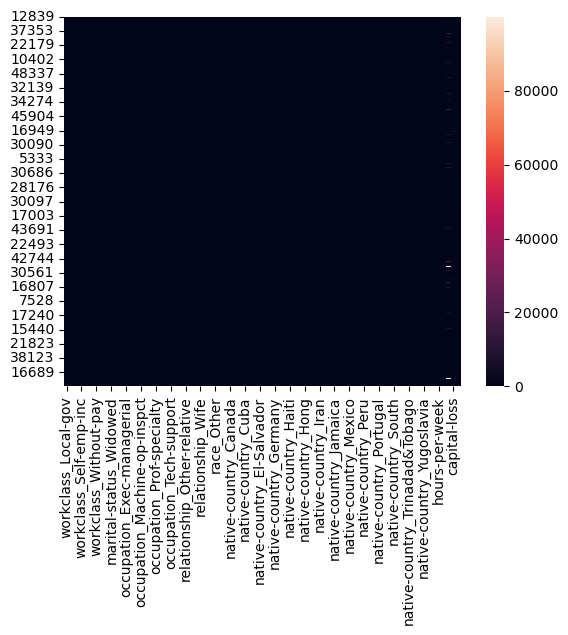

In [31]:
sns.heatmap(X_train)
plt.show()

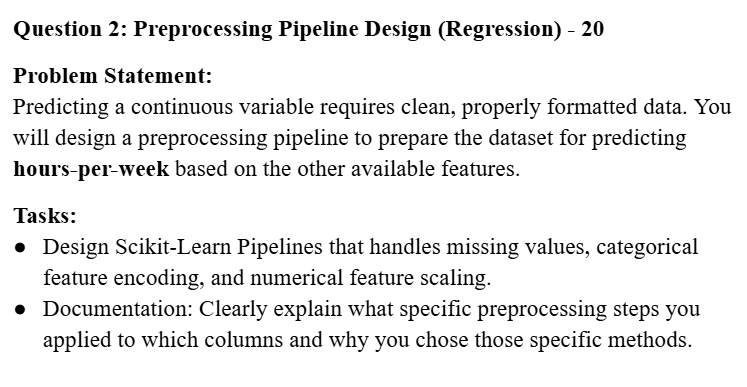

In [40]:
df=pd.read_csv("./dataset/adult_income.csv")

print(df["income"].value_counts())
# here we can see there are 4 distinct
# categories in income section: <=50K <=50K. >50K >50K. 
# so we can convert this into 2 with only binary classification.
df.loc[df["income"].str.contains('<=50K'),"income"]='0'
df.loc[df["income"].str.contains('>50K'),"income"]='1'
df["income"]=df["income"].astype(int)

print(df["income"].value_counts())

non_numeric_cols=df.select_dtypes(include=['object']).columns.tolist()
numeric_cols=df.select_dtypes(include=['number']).columns.tolist()

for col in non_numeric_cols:
    print(df[col].unique()) # here if we check all columns distinct categories
    # then we can see that there is not any null or empty value but has ? mark in some box,
    # which is not expressed. so we have to process this.
    # and for that we convert this question sign into empty box
    # so that we can then impute later.
    df[col]=df[col].str.strip().replace('?',np.nan)

print(df.isnull().sum())
df=df.drop_duplicates().copy()
# here we removed some duplicate rows 
print(df.shape)

X=df.drop(columns=['hours-per-week','education','fnlwgt'])

# if we observe this dataset and the problem we need to solve then we can say that
# fnlwgt is not needed right now for linear regression or knn or logistic regression. 
# fnlwgt= final weight - It's a census sampling weight, not an ordinary personal measurement.
#
# the education-num and education both features are same. one in string and another is
# in the number form . where each category is given number by their level. 
# like hsc is lower than msc or doctorate. 
#
# and as we have to predict hours-per-week that's why we kept it alone as a target.

y=df['hours-per-week']

# print(y)
encode_col=['workclass','marital-status','occupation','relationship','race','sex','native-country']
scaling_col=['age']

# as all most of the values of capital-gain and capital-loss features are near zero that's why
# we did not choose this for scaling as this already are carrying minimum value .


non_numeric_cols=X.select_dtypes(include=['object']).columns.tolist()
numeric_cols=X.select_dtypes(include=['number']).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)


cat_pipe=Pipeline([
    ('imputer',SimpleImputer(missing_values=np.nan ,strategy="most_frequent")),
    ('le',OneHotEncoder(sparse_output=False,drop='first',handle_unknown="infrequent_if_exist",
    min_frequency=50))
    # we choose simpleimputer for impute nan or empty cell with most frequent mentioned data.
    # we choose onehotencoder as becuase the feature we are trying to encode has not any
    # level wise relation. all are different. and we can't say this is better than that.
    # min_frequency=50 tells the encoder to group categories that occur fewer than 50 times
    # in the fitted training data into an infrequent category.
])

num_pipe=Pipeline([
    ('imputer',SimpleImputer(missing_values=np.nan ,strategy="median")),
    ('ss',StandardScaler())
    
])
# in num_pipe we use median value for impute the numerical feature's empty or nan cell.
# and after imputation we scale the values into a certain range so that much difference doesnot
# make any biasness like this features are more prioritise than other.


preprocessor_trans=ColumnTransformer(
    transformers=[
        
        ('numerical',num_pipe,numeric_cols),
        ('categorical',cat_pipe,non_numeric_cols)
        # ('numerical',num_pipe,scaling_col),
        # ('categorical',cat_pipe,encode_col)
    ],
    remainder='drop',verbose_feature_names_out=False
)

# .set_output(transform='pandas')

# imputer_transformer.fit(X_train)

# X_train = imputer_transformer.transform(X_train)
# X_test=imputer_transformer.transform(X_test)



income
<=50K     24720
<=50K.    12435
>50K       7841
>50K.      3846
Name: count, dtype: int64
income
0    37155
1    11687
Name: count, dtype: int64
[' State-gov' ' Self-emp-not-inc' ' Private' ' Federal-gov' ' Local-gov'
 ' ?' ' Self-emp-inc' ' Without-pay' ' Never-worked']
[' Bachelors' ' HS-grad' ' 11th' ' Masters' ' 9th' ' Some-college'
 ' Assoc-acdm' ' Assoc-voc' ' 7th-8th' ' Doctorate' ' Prof-school'
 ' 5th-6th' ' 10th' ' 1st-4th' ' Preschool' ' 12th']
[' Never-married' ' Married-civ-spouse' ' Divorced'
 ' Married-spouse-absent' ' Separated' ' Married-AF-spouse' ' Widowed']
[' Adm-clerical' ' Exec-managerial' ' Handlers-cleaners' ' Prof-specialty'
 ' Other-service' ' Sales' ' Craft-repair' ' Transport-moving'
 ' Farming-fishing' ' Machine-op-inspct' ' Tech-support' ' ?'
 ' Protective-serv' ' Armed-Forces' ' Priv-house-serv']
[' Not-in-family' ' Husband' ' Wife' ' Own-child' ' Unmarried'
 ' Other-relative']
[' White' ' Black' ' Asian-Pac-Islander' ' Amer-Indian-Eskimo' ' Other'

In [41]:
# Question3
regression_results=[]

lr_model=Pipeline(steps=[
    ("preprocessor",preprocessor_trans),
    ("model",LinearRegression())
])

lr_model.fit(X_train,y_train)

pred=lr_model.predict(X_test)

regression_results.append({
    "Model":"Linear Regression",
    "R2":r2_score(y_test,pred),
    "MAE_hours": mean_absolute_error(y_test, pred),
    "MSE": mean_squared_error(y_test, pred),
    "RMSE_hours": mean_squared_error(y_test, pred) ** 0.5
})

sgdr_model=Pipeline(steps=[
    ("preprocessor",preprocessor_trans),
    ("model",SGDRegressor(
        max_iter=1000,
        random_state=42,
        eta0=0.01,learning_rate="adaptive"
    ))
])

sgdr_model.fit(X_train,y_train)

pred=sgdr_model.predict(X_test)

regression_results.append({
    "Model":"SGD Regression",
    "R2":r2_score(y_test,pred),
    "MAE_hours": mean_absolute_error(y_test, pred),
    "MSE": mean_squared_error(y_test, pred),
    "RMSE_hours": mean_squared_error(y_test, pred) ** 0.5
})
result=pd.DataFrame(regression_results).set_index("Model")
display(result.round(4))

,R2,MAE_hours,MSE,RMSE_hours
Model,,,,
Linear Regression,0.1626,7.7413,124.2690,11.1476
SGD Regression,0.1628,7.7398,124.2476,11.1466


In [44]:
# Question4
df=pd.read_csv("./dataset/adult_income.csv")

# print(df["income"].value_counts())
df.loc[df["income"].str.contains('<=50K'),"income"]='0'
df.loc[df["income"].str.contains('>50K'),"income"]='1'
df["income"]=df["income"].astype(int)

# print(df["income"].value_counts())

non_numeric_cols=df.select_dtypes(include=['object']).columns.tolist()
numeric_cols=df.select_dtypes(include=['number']).columns.tolist()

for col in non_numeric_cols: 
    df[col]=df[col].str.strip().replace('?',np.nan)

# print(df.isnull().sum())
df=df.drop_duplicates().copy() 
# print(df.shape)

X=df.drop(columns=['income','education','fnlwgt'])
 
y=df['income']

non_numeric_cols=X.select_dtypes(include=['object']).columns.tolist()

numeric_cols=X.select_dtypes(include=['number']).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

cat_pipe=Pipeline([
    ('imputer',SimpleImputer(missing_values=np.nan ,strategy="most_frequent")),
    ('le',OneHotEncoder(sparse_output=False,drop='first',handle_unknown="infrequent_if_exist",
    min_frequency=50))
    
])

num_pipe=Pipeline([
    ('imputer',SimpleImputer(missing_values=np.nan ,strategy="median")),
    ('ss',StandardScaler())
    
])
 

preprocessor_trans=ColumnTransformer(
    transformers=[
        ('numerical',num_pipe,numeric_cols),
        ('categorical',cat_pipe,non_numeric_cols)
    ],
    remainder='drop',verbose_feature_names_out=False
)


lr_model=Pipeline(steps=[
    ("preprocessor",preprocessor_trans),
    ("model",LogisticRegression(max_iter=1000,random_state=42))
])

lr_model.fit(X_train,y_train)

pred=lr_model.predict(X_test)

lr_res=({
    "Accuracy":accuracy_score(y_test,pred),
    "Precision(>50k)": precision_score(y_test, pred),
    "Recall(>50k)": recall_score(y_test, pred)
})



result=pd.Series(lr_res,name="Logistic Regression").to_frame()
display(result.round(4))

cm_logistic = confusion_matrix(y_test, pred, labels=[0, 1])
print("Confusion matrix (rows = actual [<=50K, >50K], columns = predicted [<=50K, >50K]):")
display(pd.DataFrame(cm_logistic,
                     index=["Actual <=50K", "Actual >50K"],
                     columns=["Predicted <=50K", "Predicted >50K"]))

print("Classification report:")
print(classification_report(y_test, pred, target_names=["<=50K", ">50K"], digits=4))

,Logistic Regression
Accuracy,0.8535
Precision(>50k),0.7325
Recall(>50k),0.6109


Confusion matrix (rows = actual [<=50K, >50K], columns = predicted [<=50K, >50K]):


,Predicted <=50K,Predicted >50K
Actual <=50K,6901,521
Actual >50K,909,1427


Classification report:
              precision    recall  f1-score   support

       <=50K     0.8836    0.9298    0.9061      7422
        >50K     0.7325    0.6109    0.6662      2336

    accuracy                         0.8535      9758
   macro avg     0.8081    0.7703    0.7862      9758
weighted avg     0.8474    0.8535    0.8487      9758



In [ ]:
#Question 5

df=pd.read_csv("./dataset/adult_income.csv")

# print(df["income"].value_counts())
df.loc[df["income"].str.contains('<=50K'),"income"]='0'
df.loc[df["income"].str.contains('>50K'),"income"]='1'
df["income"]=df["income"].astype(int)

# print(df["income"].value_counts())

non_numeric_cols=df.select_dtypes(include=['object']).columns.tolist()
numeric_cols=df.select_dtypes(include=['number']).columns.tolist()

for col in non_numeric_cols: 
    df[col]=df[col].str.strip().replace('?',np.nan)

# print(df.isnull().sum())
df=df.drop_duplicates().copy() 
# print(df.shape)

X=df.drop(columns=['income','education','fnlwgt'])
 
y=df['income']

non_numeric_cols=X.select_dtypes(include=['object']).columns.tolist()

numeric_cols=X.select_dtypes(include=['number']).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

cat_pipe=Pipeline([
    ('imputer',SimpleImputer(missing_values=np.nan ,strategy="most_frequent")),
    ('le',OneHotEncoder(sparse_output=False,handle_unknown="infrequent_if_exist",
    min_frequency=50))
    
])

num_pipe=Pipeline([
    ('imputer',SimpleImputer(missing_values=np.nan ,strategy="median")),
    ('ss',StandardScaler())
    
])
 

preprocessor_trans=ColumnTransformer(
    transformers=[
        ('numerical',num_pipe,numeric_cols),
        ('categorical',cat_pipe,non_numeric_cols)
    ],
    remainder='drop',verbose_feature_names_out=False
)


pipe=Pipeline(steps=[
    ("preprocessor",preprocessor_trans),
    ("model",KNeighborsClassifier())
])

param={
    'model__n_neighbors':[3,5,7,11,13,17,19,21],
    'model__weights': ['uniform', 'distance'],
    'model__metric': ['euclidean', 'manhattan']    
}
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
grid_search=GridSearchCV(
    estimator=pipe,
    param_grid=param,
    cv=cv,
    scoring="f1",
    n_jobs=-1,
    refit=True
    
)

grid_search.fit(X_train,y_train)
print("Best cv:",grid_search.best_score_)
print(grid_search.best_params_)
knn_model = grid_search.best_estimator_
pred=knn_model.predict(X_test)

knn_res=({
    "Accuracy":accuracy_score(y_test,pred),
    "Precision(>50k)": precision_score(y_test, pred),
    "Recall(>50k)": recall_score(y_test, pred)
})

compare=pd.DataFrame({
    "Logistic Regression": lr_res,
    "Tuned KNN":knn_res})
display(compare)

# result=pd.Series(lr_res,name="Logistic Regression").to_frame()
# display(result.round(4))